<a href="https://colab.research.google.com/github/suhailnoor1821/CRM_CW1_Stock_Segmentation/blob/main/CRM_CW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1.1 Ticker selection and data acquisition
* Tickers: S&P 500 list from Wikipedia (`pd.read_html`), as in Tutorials 04/05.
* Prices: **yfinance** (used in the seminars). `auto_adjust=False` gives both `Adj Close` (for returns and beta) and `Close` (for Monetary); `actions=True` adds dividends and splits for the corporate-action checks.
* Benchmark: `^GSPC`. Period: 1 Jan 2021 to 1 Jan 2025 (end date exclusive).
* **Snapshot:** prices change over time, so the data were downloaded **once on 14 Nov 2026** and saved in the GitHub repository (`data/data_snapshot_2026-11-14`). Every run loads these saved files; the download code only runs if the files are missing.

In [ ]:
# Install the yfinance library (used to download share prices)
!pip install -q yfinance

In [ ]:
# Import the libraries we need
import os
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Study dates: 1 Jan 2021 to 1 Jan 2025 (the end date itself is not included)
start = '2021-01-01'
end = '2025-01-01'
retrieval_date = '2026-11-14'      # the day we downloaded the data

# Get the saved data (snapshot) from the GitHub repository, so anyone can run this notebook
folder = '/content/CRM_CW1_Stock_Segmentation'
if not os.path.exists(folder):
    !git clone -q https://github.com/suhailnoor1821/CRM_CW1_Stock_Segmentation.git {folder}
snapshot_dir = f'{folder}/data/data_snapshot_{retrieval_date}'
output_dir = f'{folder}/outputs'
os.makedirs(snapshot_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# Show the package versions (the brief asks for them)
print('pandas', pd.__version__, '| numpy', np.__version__, '| yfinance', yf.__version__)

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66


In [ ]:
# Task 1.1 Part 1: Get the list of S&P 500 companies from Wikipedia
# This runs only the first time. After that, the saved list is used
ticker_file = f'{snapshot_dir}/sp500_constituents.csv'

if not os.path.exists(ticker_file):
    # Wikipedia blocks requests without a User-Agent, so we send one
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    sp500_df = table[0]
    # Yahoo writes BRK.B as BRK-B, so change '.' to '-'
    sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
    sp500_df['Retrieval_Date'] = retrieval_date
    sp500_df.to_csv(ticker_file, index=False)

# Load the saved list
sp500_df = pd.read_csv(ticker_file, keep_default_na=False)
tickers = sp500_df['Ticker'].tolist()

print('Total tickers extracted:', len(tickers), '| retrieved on', retrieval_date)
sp500_df[['Symbol', 'Ticker', 'Security', 'GICS Sector', 'Date added']].head(10)

Total tickers extracted: 503 | retrieved on 2026-11-14


,Symbol,Ticker,Security,GICS Sector,Date added
0,MMM,MMM,3M,Industrials,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,ACN,Accenture,Information Technology,2011-07-06
5,ADBE,ADBE,Adobe Inc.,Information Technology,1997-05-05
6,AMD,AMD,Advanced Micro Devices,Information Technology,2017-03-20
7,AES,AES,AES Corporation,Utilities,1998-10-02
8,AFL,AFL,Aflac,Financials,1999-05-28
9,A,A,Agilent Technologies,Health Care,2000-06-05


In [ ]:
# Task 1.1 Part 2: Daily prices and volume for every share and for the S&P 500 (^GSPC)
# The download runs only if the saved files are missing. After that, the saved files are used
if not os.path.exists(f'{snapshot_dir}/adj_close_daily.csv.gz'):
    df = yf.download(tickers, start=start, end=end, auto_adjust=False, actions=True)
    df['Adj Close'].to_csv(f'{snapshot_dir}/adj_close_daily.csv.gz')
    df['Close'].to_csv(f'{snapshot_dir}/close_daily.csv.gz')
    df['Volume'].to_csv(f'{snapshot_dir}/volume_daily.csv.gz')
    df['Dividends'].to_csv(f'{snapshot_dir}/dividends_daily.csv.gz')
    df['Stock Splits'].to_csv(f'{snapshot_dir}/splits_daily.csv.gz')

    # Download the S&P 500 index (the benchmark)
    market = yf.download('^GSPC', start=start, end=end, auto_adjust=False)
    market.columns = market.columns.get_level_values(0)
    market[['Adj Close', 'Close', 'Volume']].to_csv(f'{snapshot_dir}/gspc_daily.csv.gz')

# Small helper that reads one saved file
def load(name):
    return pd.read_csv(f'{snapshot_dir}/{name}_daily.csv.gz', index_col=0, parse_dates=True)

adj_close = load('adj_close')
close = load('close')
volume = load('volume')
dividends = load('dividends')
splits = load('splits')
gspc = load('gspc')        # S&P 500 index (benchmark)

print('Shares:', adj_close.shape[1], '| trading days:', adj_close.shape[0],
      '| first:', adj_close.index.min().date(), '| last:', adj_close.index.max().date())

Shares: 503 | trading days: 1005 | first: 2021-01-04 | last: 2024-12-31


In [ ]:
# Find tickers where Yahoo Finance gave no data at all
no_data = [t for t in tickers if t not in adj_close.columns or adj_close[t].isna().all()]
print('Tickers with no data:', len(no_data), no_data)

Tickers with no data: 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


## 1.2 Data validation and alignment
The tutorial code filled gaps with `ffill`/`bfill`. The brief says **do not silently fill missing prices**, so each share is checked instead and **excluded** (with a reason) if it has:
* no data, or a history that starts after 4 Jan 2021 / ends before 31 Dec 2024 (unequal history)
* any missing day, a zero/negative price, or a zero/negative volume
* a price jump on a stock-split day (meaning the prices are not split-adjusted)

In [ ]:
# Task 1.2 Part 1: Check for duplicate dates and missing S&P 500 prices
print('Trading days:', len(gspc), '| first:', gspc.index.min().date(), '| last:', gspc.index.max().date())
print('Duplicate dates - shares:', adj_close.index.duplicated().sum(), '| benchmark:', gspc.index.duplicated().sum())
print('Missing benchmark prices:', gspc['Adj Close'].isna().sum())
print('Benchmark Adj Close equals Close:', np.allclose(gspc['Adj Close'], gspc['Close']))

# Put every share on the same trading days as the S&P 500
# Missing days stay empty - we do NOT fill them
adj_close = adj_close.reindex(gspc.index)
close = close.reindex(gspc.index)
volume = volume.reindex(gspc.index)
dividends = dividends.reindex(gspc.index).fillna(0)   # 0 = no dividend that day
splits = splits.reindex(gspc.index).fillna(0)         # 0 = no split that day

Trading days: 1005 | first: 2021-01-04 | last: 2024-12-31
Duplicate dates - shares: 0 | benchmark: 0
Missing benchmark prices: 0
Benchmark Adj Close equals Close: True


In [ ]:
# Task 1.2 Part 2: Check every share and write down why a share is removed
first_day = gspc.index[0]
last_day = gspc.index[-1]

# One row per share: first date, last date and how many days have problems
checks = pd.DataFrame(index=adj_close.columns)
checks['First_Date'] = adj_close.apply(lambda s: s.first_valid_index())
checks['Last_Date'] = adj_close.apply(lambda s: s.last_valid_index())
checks['Missing_Days'] = (adj_close.isna() | close.isna() | volume.isna()).sum()
checks['Bad_Price_Days'] = ((adj_close <= 0) | (close <= 0)).sum()
checks['Zero_Volume_Days'] = (volume <= 0).sum()
checks['Splits'] = (splits > 0).sum()
checks['Dividends'] = (dividends > 0).sum()

# Stock splits: Yahoo already adjusts prices for splits,
# so the Close price should NOT jump on a split day
daily_change = (close / close.shift(1) - 1).abs()
checks['Change_On_Split_Day'] = daily_change.where(splits > 0).max()

checks = checks.reindex(tickers)      # one row for every ticker on the Wikipedia list

# Give the reason a share is removed (empty text = the share is kept)
def exclusion_reason(row):
    if pd.isna(row['First_Date']):
        return 'No data from Yahoo Finance'
    if row['First_Date'] > first_day:
        return f"Listed after study start ({row['First_Date'].date()})"
    if row['Last_Date'] < last_day:
        return f"History ends early ({row['Last_Date'].date()})"
    if row['Missing_Days'] > 0:
        return f"{int(row['Missing_Days'])} missing days"
    if row['Bad_Price_Days'] > 0:
        return 'Zero or negative price'
    if row['Zero_Volume_Days'] > 0:
        return f"{int(row['Zero_Volume_Days'])} zero-volume days"
    if row['Change_On_Split_Day'] > 0.25:
        return 'Price jump on split day'
    return ''

checks['Exclusion_Reason'] = checks.apply(exclusion_reason, axis=1)
checks = checks.join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
# List of shares that passed every check
included = checks.index[checks['Exclusion_Reason'] == ''].tolist()

print('Tickers on the list:', len(checks), '| retained:', len(included), '| excluded:', len(checks) - len(included))
checks.loc[checks['Exclusion_Reason'] != '', ['Security', 'GICS Sector', 'First_Date', 'Exclusion_Reason']]

Tickers on the list: 503 | retained: 486 | excluded: 17


,Security,GICS Sector,First_Date,Exclusion_Reason
APP,AppLovin,Communication Services,2021-04-15,Listed after study start (2021-04-15)
COIN,Coinbase,Financials,2021-04-14,Listed after study start (2021-04-14)
CEG,Constellation Energy,Utilities,2022-01-19,Listed after study start (2022-01-19)
EXE,Expand Energy,Energy,2021-02-10,Listed after study start (2021-02-10)
FDXF,FedEx Freight,Industrials,NaT,No data from Yahoo Finance
FERG,Ferguson Enterprises,Industrials,2021-01-04,27 zero-volume days
GEHC,GE HealthCare,Health Care,2022-12-15,Listed after study start (2022-12-15)
GEV,GE Vernova,Industrials,2024-03-27,Listed after study start (2024-03-27)
HONA,Honeywell Aerospace,Industrials,NaT,No data from Yahoo Finance
Q,Qnity Electronics,Information Technology,NaT,No data from Yahoo Finance


In [ ]:
# Task 1.2 Part 3: Summary of the checks for the shares we kept
kept = checks.loc[included]
print('Missing days:', int(kept['Missing_Days'].sum()),
      '| bad prices:', int(kept['Bad_Price_Days'].sum()),
      '| zero volumes:', int(kept['Zero_Volume_Days'].sum()))
print('Shares with a stock split:', int((kept['Splits'] > 0).sum()),
      '| largest Close change on a split day:', round(kept['Change_On_Split_Day'].max(), 4))
print('Shares paying dividends:', int((kept['Dividends'] > 0).sum()))

# Adj Close / Close should only change on a dividend or split day
# (0 below means every change is explained)
factor_change = (adj_close / close).pct_change(fill_method=None).abs() > 0.001
unexplained = factor_change & (dividends == 0) & (splits == 0)
print('Adjustment changes NOT on a dividend/split day:', int(unexplained[included].sum().sum()))

# Save the check results
checks.to_csv(f'{output_dir}/validation_log.csv')

# Show all stock splits for the shares we kept
split_list = splits[included].stack()
split_list[split_list > 0].rename('Split_Ratio').to_frame()

Missing days: 0 | bad prices: 0 | zero volumes: 0
Shares with a stock split: 53 | largest Close change on a split day: 0.0766
Shares paying dividends: 392
Adjustment changes NOT on a dividend/split day: 0


,,Split_Ratio
Date,,
2021-03-05,APH,2.000
2021-04-01,SHW,3.000
2021-06-03,MRK,1.048
2021-06-28,CSGP,10.000
2021-06-29,CSX,3.000
...,...,...
2024-10-03,LRCX,10.000
2024-12-04,ANET,4.000
2024-12-13,ETR,2.000


**Survivorship bias.** The ticker list is today's S&P 500, applied back to 2021–2024. Companies that left the index during the period (acquired, delisted, removed) are missing, and companies that grew into the index are included, so the sample favours past winners. Shares listed after January 2021 are also excluded, so the retained set is "current members with a full 2021–2024 history", not the historical index.

## 1.3 Weekly return and weekly beta
* Daily `Adj Close` → Friday-ending weeks (`W-FRI`), using the last available price in each week (Thursday if Friday is a holiday).
* Weekly return = this week's price / last week's price − 1. Missing weeks are not filled.
* Incomplete first/final calendar weeks are removed (this drops 30–31 Dec 2024); holiday-shortened weeks are kept.
* Shares and the benchmark use the same week labels.

In [ ]:
# Turn the table round: one row per share, one column per date (same as the tutorials)
df1 = adj_close[included].T
print('Shape after transpose:', df1.shape)

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    # Take the last price of each week (weeks end on Friday)
    weekly_prices = prices.resample("W-FRI").last()

    # Added for the brief: keep only full weeks inside the study dates
    # (this removes the half week 30-31 Dec 2024)
    monday = weekly_prices.index - pd.Timedelta(days=4)
    weekly_prices = weekly_prices[(monday >= start) & (weekly_prices.index < end)]
    # Weekly return = this week's price / last week's price - 1
    return weekly_prices.pct_change(fill_method=None)

Shape after transpose: (486, 1005)


In [ ]:
# Weekly returns for all shares and for the S&P 500
# .iloc[1:] drops the first week because it has no week before it
weekly_returns = calculate_weekly_returns(df1).iloc[1:]
market_weekly_returns = calculate_weekly_returns(gspc[['Adj Close']].T).iloc[1:]
market_weekly_returns.columns = ['^GSPC']

# Checks: shares and S&P 500 use the same weeks, every week ends on Friday, nothing is missing
print('Same week labels for shares and benchmark:', weekly_returns.index.equals(market_weekly_returns.index))
print('All week labels are Fridays:', (weekly_returns.index.dayofweek == 4).all())
print('Weeks:', len(weekly_returns), '| first:', weekly_returns.index[0].date(), '| last:', weekly_returns.index[-1].date())
print('Missing weekly returns:', weekly_returns.isna().sum().sum())
weekly_returns

Same week labels for shares and benchmark: True
All week labels are Fridays: True
Weeks: 207 | first: 2021-01-15 | last: 2024-12-27
Missing weekly returns: 0


,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006421,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012165,-0.036134,-0.004947,0.009249,0.007361,-0.038963
2021-01-22,0.021081,0.016365,0.013836,0.003077,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011484,-0.003079,-0.008695,0.004408,-0.000929,0.005558,0.012522
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060988,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609
2021-02-12,0.006494,0.006167,0.033863,-0.039456,0.015500,0.013655,0.066780,0.062174,0.032343,0.038967,...,0.033952,0.015676,0.065959,0.007351,-0.029950,0.009471,0.006033,0.173491,0.009319,0.046647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.039791,0.014297,0.008577,0.033795,0.010344,0.007381,-0.008457,0.000000,0.014325,0.030858,...,-0.018944,0.024173,-0.066331,0.033848,0.016959,0.001851,0.027131,0.024699,0.017057,-0.009663
2024-12-06,-0.003145,-0.025238,-0.026690,-0.036844,0.000911,0.071773,0.010278,0.000767,-0.058684,0.018917,...,-0.028537,0.001770,0.065723,-0.000106,-0.038864,-0.002998,-0.004629,0.005700,-0.036307,0.006904
2024-12-13,-0.023965,-0.001653,-0.019204,-0.016005,-0.011083,-0.157823,-0.084277,0.022989,-0.026000,-0.011239,...,-0.034256,-0.034659,0.027213,0.001695,-0.023229,-0.045660,-0.004577,-0.013999,-0.011941,0.009747


In [ ]:
# Count the trading days in each week (holiday weeks have fewer than 5)
days_per_week = pd.Series(1, index=gspc.index).resample('W-FRI').sum()
print('Removed incomplete final week:', days_per_week.index[-1].date(), '-', days_per_week.iloc[-1], 'trading days')
print('Holiday-shortened weeks kept (< 5 days):', (days_per_week.loc[weekly_returns.index] < 5).sum())

Removed incomplete final week: 2025-01-03 - 2 trading days
Holiday-shortened weeks kept (< 5 days): 37


### 1.3.1 Mean weekly return
The arithmetic mean of the 207 weekly returns for each share (0.003 = 0.3% per week).

In [ ]:
# Task 1.3.1: Average weekly return of each share over the whole period
mean_weekly_return = weekly_returns.mean()
print('Weekly observations per share:', weekly_returns.count().unique())
mean_weekly_return.describe()

Weekly observations per share: [207]


,0
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


In [ ]:
# Check one AAPL weekly return by hand (price this week / price last week - 1)
week = weekly_returns.index[10]
price_now = adj_close.loc[:week, 'AAPL'].iloc[-1]
price_before = adj_close.loc[:week - pd.Timedelta(days=7), 'AAPL'].iloc[-1]
print(week.date(), '| manual:', round(price_now / price_before - 1, 6), '| code:', round(weekly_returns.loc[week, 'AAPL'], 6))

2021-03-26 | manual: 0.010167 | code: 0.010167


### 1.3.2 Weekly beta
Beta = Cov(share, market weekly returns) / Var(market weekly returns), using the tutorial `calculate_weekly_beta` function over the full period. `Paired_weeks` = number of aligned weeks.

Share returns use `Adj Close` (includes dividends) but `^GSPC` is a price index (no dividends). To test this, beta is also calculated with `Close` prices for the shares.

In [ ]:
# Task 1.3.2: Weekly beta = covariance(share, market) / variance(market)
# This function is the same as in Tutorials 04/05
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

# Work out beta for every share
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns["^GSPC"])
beta_df.describe()

,Beta,Paired_weeks
count,486.000000,486.0
mean,0.973695,207.0
std,0.407339,0.0
min,0.055452,207.0
25%,0.666599,207.0
50%,0.950609,207.0
75%,1.179538,207.0
max,3.778560,207.0


In [ ]:
# Check AAPL beta another way: the slope of a straight line fitted to the returns should equal beta
share = weekly_returns['AAPL']
market = market_weekly_returns['^GSPC']
slope = np.polyfit(market, share, 1)[0]
print('AAPL beta - function:', round(beta_df.loc['AAPL', 'Beta'], 4), '| regression slope:', round(slope, 4),
      '| weeks:', beta_df.loc['AAPL', 'Paired_weeks'])

AAPL beta - function: 1.1748 | regression slope: 1.1748 | weeks: 207


In [ ]:
# Extra check: beta using Close prices (no dividends), because the S&P 500 index has no dividends either
# If the two betas are almost the same, the price choice does not matter
weekly_close = calculate_weekly_returns(close[included].T).iloc[1:]
beta_close = calculate_weekly_beta(weekly_close, market_weekly_returns['^GSPC'])['Beta']

print('Correlation between Adj Close beta and Close beta:', round(beta_df['Beta'].corr(beta_close), 4))
print('Largest difference:', round((beta_df['Beta'] - beta_close).abs().max(), 4))

Correlation between Adj Close beta and Close beta: 0.9999
Largest difference: 0.0171


## 1.4 Adapted RFM (trading activity)
Same method as the Tutorial 03 RFM code, run for every retained share:
* **Observation date:** last common trading date (31 Dec 2024).
* **High-volume day:** volume > 2 × average volume of the previous 20 days (the day itself is not included).
* **Recency:** calendar days from the latest high-volume day to the observation date (missing if there is none).
* **Frequency:** number of high-volume days in the latest 60 trading days.
* **Monetary:** sum of Close × Volume over the latest 60 trading days (USD) – traded value, not market value.

In [ ]:
# Task 1.4: RFM for every share (same code as Tutorial 03)
# Observation date = last trading day in the data (31 Dec 2024)
observation_date = gspc.index[-1]
print('Observation date:', observation_date.date(),
      '| all retained shares have data on it:', adj_close.loc[observation_date, included].notna().all())

results = []

for ticker in included:
    data = pd.DataFrame({"Close": close[ticker], "Volume": volume[ticker]})

    # Average of the previous 20 days, excluding the current day.
    average_volume = data["Volume"].shift(1).rolling(20).mean()

    # High-volume day = volume more than 2 x that average
    data["HighVolume"] = data["Volume"] > 2 * average_volume

    # Only consider days with a complete volume baseline.
    valid = data.loc[average_volume.notna()].copy()

    if len(valid) < 60:
        print(f"{ticker}: insufficient history")
        continue

    # Last 60 trading days (used for Frequency and Monetary)
    recent = valid.tail(60)
    high_volume_days = valid.loc[valid["HighVolume"]]

    # Recency in calendar days, measured at the observation date.
    # No event in the history is recorded as missing.
    recency = (
        (observation_date.date() - high_volume_days.index[-1].date()).days
        if not high_volume_days.empty
        else None
    )

    # Frequency = number of high-volume days in the last 60 days
    # Monetary = sum of Close x Volume over the last 60 days (USD)
    results.append({
        "Share": ticker,
        "Last_Event": high_volume_days.index[-1].date() if not high_volume_days.empty else None,
        "Recency": recency,
        "Frequency": int(recent["HighVolume"].sum()),
        "Monetary": round((recent["Close"] * recent["Volume"]).sum(), 2)
    })

# Put the results into one table
rfm = pd.DataFrame(results).set_index("Share")
rfm["Recency"] = rfm["Recency"].astype("Int64")
rfm.head(10)

Observation date: 2024-12-31 | all retained shares have data on it: True


,Last_Event,Recency,Frequency,Monetary
Share,,,,
MMM,2024-12-20,11,4,2.599146e+10
AOS,2024-12-20,11,2,4.748980e+09
ABT,2024-12-20,11,1,3.523027e+10
ABBV,2024-12-20,11,3,6.837054e+10
ACN,2024-12-20,11,2,5.199430e+10
ADBE,2024-12-13,18,3,1.030403e+11
AMD,2024-12-13,18,4,3.131659e+11
AES,2024-11-07,54,3,1.119578e+10
AFL,2024-12-20,11,2,1.328456e+10


In [ ]:
# Task 1.4 checks: missing Recency, Recency = 0 and Frequency = 0
print('Shares with RFM:', len(rfm))
print('No high-volume day (Recency missing):', rfm['Recency'].isna().sum())
print('Event on the observation date (Recency = 0):', (rfm['Recency'] == 0).sum())
print('Frequency = 0:', (rfm['Frequency'] == 0).sum())

# The brief's example: average 1 million, so the limit is 2 million
print('2.5 million qualifies:', 2_500_000 > 2 * 1_000_000, '| 1.8 million qualifies:', 1_800_000 > 2 * 1_000_000)

# Which dates were the latest high-volume day for most shares?
rfm['Last_Event'].value_counts().head(5)

Shares with RFM: 486
No high-volume day (Recency missing): 0
Event on the observation date (Recency = 0): 0
Frequency = 0: 10
2.5 million qualifies: True | 1.8 million qualifies: False


,count
Last_Event,
2024-12-20,353
2024-11-25,17
2024-11-06,11
2024-11-01,6
2024-11-15,6


**Reading Recency.** 353 of the 486 shares (72.6%) have their latest high-volume day on **20 Dec 2024** (Recency = 11 days). That day was the quarterly options/futures expiry just before the S&P quarterly index rebalance, so volume jumped across the whole market. Recency here mostly reflects a market-wide event, not share-specific news, which limits its use as a stand-alone signal.

In [ ]:
# Worked RFM example for one share (AAPL), step by step
data = pd.DataFrame({'Close': close['AAPL'], 'Volume': volume['AAPL']})
# Average volume of the 20 days before each day, and the 2x limit
data['Avg_Prev_20'] = data['Volume'].shift(1).rolling(20).mean()
data['Threshold'] = 2 * data['Avg_Prev_20']
data['HighVolume'] = data['Volume'] > data['Threshold']
# Traded value of each day = Close x Volume
data['Traded_Value'] = data['Close'] * data['Volume']
# Keep the last 60 trading days
recent = data.tail(60)

print('Latest 60 trading days:', recent.index[0].date(), 'to', recent.index[-1].date())
print('\nHigh-volume days in these 60 days:')
print(recent[recent['HighVolume']].to_string())

# Recency = days from the latest high-volume day to 31 Dec 2024
last_event = data.index[data['HighVolume']][-1]
print('\nRecency   =', observation_date.date(), '-', last_event.date(), '=', (observation_date - last_event).days, 'days')
print('Frequency =', recent['HighVolume'].sum(), 'high-volume days')
print(f"Monetary  = ${recent['Traded_Value'].sum():,.0f}")
print('RFM code result:', rfm.loc['AAPL', ['Recency', 'Frequency', 'Monetary']].to_dict())

# Check the 20-day average by hand for the latest high-volume day
pos = data.index.get_loc(last_event)
print('\nHand check - average of the 20 days before', last_event.date(), '=', data['Volume'].iloc[pos - 20:pos].mean(),
      '| code:', data.loc[last_event, 'Avg_Prev_20'])
recent.to_csv(f'{output_dir}/worked_rfm_example_AAPL.csv')

Latest 60 trading days: 2024-10-07 to 2024-12-31

High-volume days in these 60 days:
                 Close     Volume  Avg_Prev_20   Threshold  HighVolume  Traded_Value
Date                                                                                
2024-11-25  232.869995   90152800   43820740.0  87641480.0        True  2.099388e+10
2024-12-20  254.490005  147495300   45004605.0  90009210.0        True  3.753608e+10

Recency   = 2024-12-31 - 2024-12-20 = 11 days
Frequency = 2 high-volume days
Monetary  = $623,303,377,707
RFM code result: {'Recency': 11, 'Frequency': 2, 'Monetary': 623303377706.58}

Hand check - average of the 20 days before 2024-12-20 = 45004605.0 | code: 45004605.0


## 1.5 Feature table, summaries and inclusion/exclusion log
One row per retained share. Shares with all five features form the **common share set** used for every clustering in Task 2.

In [ ]:
# Task 1.5: Feature table - one row per share with all five features
feature_table = sp500_df.set_index('Ticker').loc[included, ['Security', 'GICS Sector']]
feature_table['Mean_Weekly_Return'] = mean_weekly_return
feature_table['Weekly_Beta'] = beta_df['Beta']
feature_table['Weekly_Obs'] = beta_df['Paired_weeks']
feature_table['Recency'] = rfm['Recency']
feature_table['Frequency'] = rfm['Frequency']
feature_table['Monetary'] = rfm['Monetary']
feature_table['Last_HighVol_Date'] = rfm['Last_Event']
feature_table['Observation_Date'] = observation_date.date()

# Common share set = shares that have all five features (used for all of Task 2)
features = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
feature_table['Common_Valid'] = feature_table[features].notna().all(axis=1)

feature_table.to_csv(f'{output_dir}/feature_table_task1.csv')
print('Shares in feature table:', len(feature_table), '| common share set:', feature_table['Common_Valid'].sum())
feature_table.head(10)

Shares in feature table: 486 | common share set: 486


,Security,GICS Sector,Mean_Weekly_Return,Weekly_Beta,Weekly_Obs,Recency,Frequency,Monetary,Last_HighVol_Date,Observation_Date,Common_Valid
Ticker,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,207,11,4,2.599146e+10,2024-12-20,2024-12-31,True
AOS,A. O. Smith,Industrials,0.001991,1.042805,207,11,2,4.748980e+09,2024-12-20,2024-12-31,True
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,11,1,3.523027e+10,2024-12-20,2024-12-31,True
ABBV,AbbVie,Health Care,0.003749,0.425367,207,11,3,6.837054e+10,2024-12-20,2024-12-31,True
ACN,Accenture,Information Technology,0.002376,1.143300,207,11,2,5.199430e+10,2024-12-20,2024-12-31,True
ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,207,18,3,1.030403e+11,2024-12-13,2024-12-31,True
AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,207,18,4,3.131659e+11,2024-12-13,2024-12-31,True
AES,AES Corporation,Utilities,-0.001420,1.143911,207,54,3,1.119578e+10,2024-11-07,2024-12-31,True
AFL,Aflac,Financials,0.005004,0.707197,207,11,2,1.328456e+10,2024-12-20,2024-12-31,True


In [ ]:
# Summary of each feature (mean, min, max, etc.) and how skewed it is
common = feature_table[feature_table['Common_Valid']]
summary = common[features].astype(float).describe().T
summary['skew'] = common[features].astype(float).skew()
summary.to_csv(f'{output_dir}/feature_summary_task1.csv')
print('Skew of log1p(Monetary):', round(np.log1p(common['Monetary']).skew(), 2))
summary

Skew of log1p(Monetary): 1.08


,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,486.0,2.857173e-03,2.651609e-03,-4.468093e-03,1.181530e-03,2.618931e-03,4.207324e-03,1.777248e-02,0.867516
Weekly_Beta,486.0,9.736952e-01,4.073389e-01,5.545243e-02,6.665995e-01,9.506092e-01,1.179538e+00,3.778560e+00,1.103649
Recency,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02,3.645784
Frequency,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.424735
Monetary,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12,11.683797


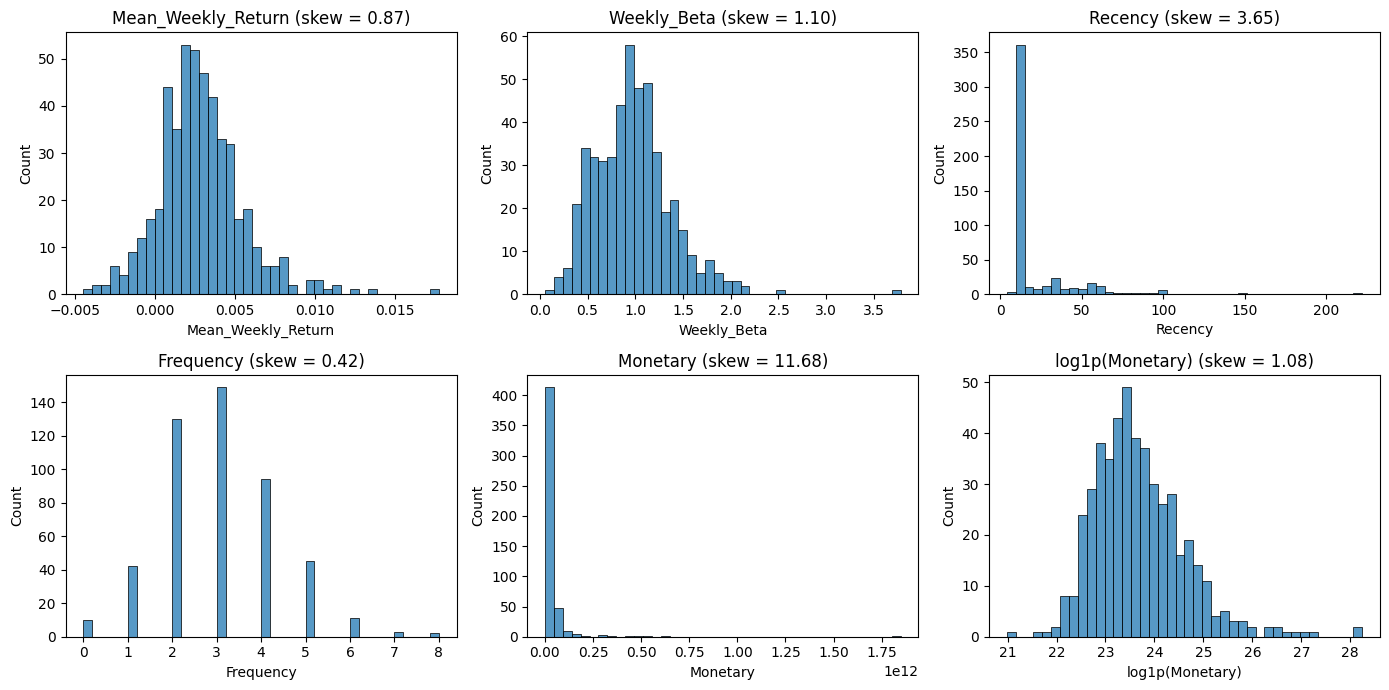

In [ ]:
# Histograms of the five features (and Monetary after log1p)
plot_data = common[features].astype(float).copy()
plot_data['log1p(Monetary)'] = np.log1p(plot_data['Monetary'])

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), plot_data.columns):
    sns.histplot(plot_data[col], bins=40, ax=ax)
    ax.set_title(f'{col} (skew = {plot_data[col].skew():.2f})')
plt.tight_layout()
plt.savefig(f'{output_dir}/feature_distributions_task1.png', dpi=150)
plt.show()

In [ ]:
# Inclusion / exclusion list: every ticker, whether it was kept, and why not
log = checks[['Security', 'GICS Sector', 'First_Date', 'Exclusion_Reason']].copy()
log['Included'] = log['Exclusion_Reason'] == ''
log['Common_Valid'] = log.index.isin(feature_table.index[feature_table['Common_Valid']])
log.to_csv(f'{output_dir}/inclusion_exclusion_log.csv')

print('Tickers on the Wikipedia list:', len(log))
print('No data from Yahoo Finance   :', (log['Exclusion_Reason'] == 'No data from Yahoo Finance').sum())
print('Passed all checks            :', log['Included'].sum())
print('Common share set (Task 2)    :', log['Common_Valid'].sum())

Tickers on the Wikipedia list: 503
No data from Yahoo Finance   : 5
Passed all checks            : 486
Common share set (Task 2)    : 486


### Metric interpretation and limits as investment signals
| Metric | What it captures | What it does **not** show |
|---|---|---|
| **Mean weekly return** | Average past weekly price change (incl. dividends), 2021–2024. | Not a future return; affected by a few extreme weeks and the period chosen. |
| **Weekly beta** | Past sensitivity to the S&P 500: β > 1 moved more than the market, β < 1 less. | Not total risk; changes over time; different betas alone do not prove diversification (correlations matter). |
| **Recency** | Days since the latest unusually high-volume day. | Not why volume rose (news, earnings, index events) or whether the price went up or down. |
| **Frequency** | Number of high-volume *days* in the latest 60 days. | Not the number of trades or shares traded. |
| **Monetary** | Approximate dollars traded in the latest 60 days (liquidity proxy). | Not market value, profit or investor inflow; spreads and price impact are not measured; very skewed, so `log1p` is used in Task 2. |

All five features describe the past only. They are not predictions of future returns, and the results depend on the snapshot date, the current-member ticker list (survivorship bias) and Yahoo Finance's price adjustments.

In [ ]:
# List the saved data and result files
for name in sorted(os.listdir(snapshot_dir)):
    print('snapshot:', name)
for name in sorted(os.listdir(output_dir)):
    print('output  :', name)

snapshot: README_snapshot.txt
snapshot: adj_close_daily.csv.gz
snapshot: close_daily.csv.gz
snapshot: dividends_daily.csv.gz
snapshot: gspc_daily.csv.gz
snapshot: snapshot_manifest.json
snapshot: sp500_constituents.csv
snapshot: splits_daily.csv.gz
snapshot: volume_daily.csv.gz
output  : README_task1.txt
output  : aapl_beta.png
output  : beta_checks.png
output  : common_valid_shares.csv
output  : exclusion_log.csv
output  : feature_distributions_task1.png
output  : feature_summary_task1.csv
output  : feature_table_task1.csv
output  : inclusion_exclusion_log.csv
output  : validation_log.csv
output  : validation_log_all_tickers.csv
output  : worked_rfm_example_AAPL.csv
output  : worked_rfm_example_AAPL.png


In [ ]:
# OPTIONAL: zip the data and results so you can download them for GitHub
# To use it, remove the # at the start of the 4 lines below and run the cell
# import shutil
# from google.colab import files
# shutil.make_archive('/content/crm_cw1_files', 'zip', folder)
# files.download('/content/crm_cw1_files.zip')